# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 1. Метрики и меры схожести между временными рядами.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы первой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [1]:
import os

practice_dir_path = 'E:/data/susu/3rd_semester/timeseriescourse/2026-Murzin-TimeSeriesCourse/practice/01 Basics'
os.chdir(practice_dir_path)

Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [2]:
%load_ext autoreload
%autoreload 2

Импортируйте библиотеки и модули, необходимые для реализации практической работы 1.

In [3]:
# !pip install sktime

In [4]:
import numpy as np
import pandas as pd
import random
from sktime.dists_kernels._numba_distances import euclidean_distance, dtw_distance, pairwise_distance
from sklearn.metrics import silhouette_score
import cv2
import imutils
import glob
import matplotlib.pyplot as plt
try:
    from google.colab.patches import cv2_imshow
except ImportError:
    def cv2_imshow(img):
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()

from modules.metrics import ED_distance, norm_ED_distance, DTW_distance
from modules.pairwise_distance import PairwiseDistance
from modules.clustering import TimeSeriesHierarchicalClustering
from modules.classification import TimeSeriesKNN, calculate_accuracy
from modules.image_converter import image2ts
from modules.utils import read_ts, z_normalize, sliding_window, random_walk
from modules.plots import plot_ts

## **Часть 1.** Функции расстояния: евклидова метрика и DTW мера. Матрица расстояний. Иерархическая кластеризация временных рядов.

### **Задача 1.**
Реализуйте самостоятельно функцию `ED_distance()` в модуле *metrics.py*, которая вычисляет евклидово расстояние между двумя временными рядами, имеющими одинаковую длину. В качестве входных данных передайте в функцию два синтетических временных ряда некоторой заданной вами длины. Для их генерации используйте функцию `random_walk()` из модуля *utils.py*,  реализующую модель случайных блужданий (Random Walk), или стандартный модуль *random*.

**Евклидово расстояние** между двумя временными рядами $T_1$ и $T_2$ длины $n$ вычисляется следующим образом:

\begin{equation}
    \text{ED}(T_1, T_2) = \sqrt{\sum_{i=1}^{n} ({t_{1}}_i-{t_{2}}_i)^2}.
\end{equation}

Проверьте реализацию функции, сравнив свои результаты с результатами функции [`euclidean_distance()`](https://www.sktime.net/en/latest/api_reference/auto_generated/sktime.distances.euclidean_distance.html) из библиотеки *sktime*, с помощью `test_distances()`.

In [5]:
def test_distances(dist1: float, dist2: float) -> None:
    """
    Check whether your distance function is implemented correctly

    Parameters
    ----------
    dist1 : distance between two time series calculated by sktime
    dist2 : distance between two time series calculated by your function
    """

    np.testing.assert_equal(round(dist1, 5), round(dist2, 5), 'Distances are not equal')

In [6]:
# INSERT YOUR CODE
n = 100

np.random.seed(42)
ts1 = random_walk(n)
ts2 = random_walk(n)

dist_my = ED_distance(ts1, ts2)
dist_sktime = euclidean_distance(ts1, ts2)

print(f"ED_distance:                 {dist_my}")
print(f"euclidean_distance(sktime):  {dist_sktime}")

test_distances(dist_sktime, dist_my)

ED_distance:                 55.31726674375732
euclidean_distance(sktime):  55.31726674375732


### **Задача 2.**

Реализуйте самостоятельно функцию `DTW_distance()` в модуле *metrics.py*, которая вычисляет DTW расстояние между двумя временными рядами, имеющими одинаковую длину. Для вычисления расстояния между элементами временных рядов в DTW мере используйте евклидово расстояние. Временные ряды сгенерируйте аналогичным образом, как в задаче 1, или используйте уже созданные.

**Динамическая трансформация временной шкалы (Dynamic Time Warping, DTW)** – мера схожести между двумя временными рядами $T_1$ и $T_2$ длины $n$, вычисляемая следующим образом:

\begin{equation}
\text{DTW}(T_1, T_2) = d(n,n),
\\ d(i,j) = ({t_{1}}_i - {t_{2}}_j)^2 + \min \left\{
	\begin{array}{l l}
	d(i-1,j), \\
	d(i,j-1), \\
	d(i-1,j-1),
	\end{array}
	\right.
\\ d(0,0)=0, \quad d(i,0)=d(0,j)=\infty, \quad  1 \leqslant i,j \leqslant n.
\end{equation}

Сравните свои результаты с результатами функции [`dtw_distance()`](https://www.sktime.net/en/latest/api_reference/auto_generated/sktime.distances.dtw_distance.html) из библиотеки *sktime*. Для этого используйте `test_distances()` из задачи 1.

In [7]:
# INSERT YOUR CODE
n = 100

np.random.seed(42)
ts1 = random_walk(n)
ts2 = random_walk(n)

dist_my = DTW_distance(ts1, ts2)

dist_sktime = dtw_distance(ts1, ts2)

print(f"DTW_distance:         {dist_my}")
print(f"dtw_distance(sktime): {dist_sktime}")

test_distances(dist_sktime, dist_my)

DTW_distance:         2288.0
dtw_distance(sktime): 2288.0


### **Задача 3.**
Реализуйте нахождение матрицы расстояний между несколькими временными рядами.
Для этого заполните все методы c недостающим кодом в классе `PairwiseDistance` из модуля *pairwise_distance.py*. Для вычисления расстояний между рядами используйте ранее реализованные вами функции `ED_distance()` и `DTW_distance()` из модуля *metrics.py*.

Матрица расстояний между временными рядами определяется следующим образом. Пусть дано множество $S$, состоящее из $K$ временных рядов длины $n$: $\;S = \{T_1, T_2, ..., T_K\}, \; T_i \in \mathbb{R}^n$. Тогда под **матрицей расстояний** $D \in \mathbb{R}^{K \times K}$ понимается квадратная матрица, где каждый ее элемент $d(i,j)$ представляет собой расстояние между временными рядами $T_i$ и $T_j$ из множества $S$:
\begin{equation}
d(i,j) = dist(T_i, T_j), \quad T_i, T_j \in S, \quad 1 \leqslant i,j \leqslant K.
\end{equation}

Поскольку евклидова метрика и DTW мера удовлетворяют аксиоме симметричности (т.е. $dist(T_i, T_j)=dist(T_j, T_i)$), то матрица расстояний $D$ будет симметричной относительно главной диагонали. Для ускорения вычислений достаточно найти ее верхний треугольник, а нижний треугольник матрицы заполнить значениями верхнего треугольника следующим образом:
\begin{equation}
d(j,i) = d(i,j), \; где \; i < j.
\end{equation}

<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/01%20Basics/img/distance_matrix.png?raw=true" width="600"></center>

Сгенерируйте множество, состоящее из $K$ временных рядов некоторой длины $n$. Вычислите матрицы евклидовых и DTW расстояний между ними. Проверьте реализованные вами методы, сравнив свои результаты с результатами функции [`pairwise_distance()`](https://www.sktime.net/en/latest/api_reference/auto_generated/sktime.distances.pairwise_distance.html) из библиотеки *sktime*.

In [8]:
def test_matrices(matrix1 : np.ndarray, matrix2 : np.ndarray) -> None:
    """
    Check whether your matrix function is implemented correctly

    Parameters
    ----------
    matrix1 : distance matrix calculated by sktime
    matrix2 : distance matrix calculated by your function
    """

    np.testing.assert_equal(matrix1.round(5), matrix2.round(5), 'Matrices are not equal')

In [9]:
# INSERT YOUR CODE

# генерируем K временных рядов длины n
K = 10
n = 100

np.random.seed(42)
ts_set = np.array([random_walk(n) for _ in range(K)])

# Евклидова метрика (без нормализации)
dist_calc = PairwiseDistance(metric='euclidean', is_normalize=False)
D_my = dist_calc.calculate(ts_set)

D_sktime = pairwise_distance(ts_set, metric='euclidean')

test_matrices(D_sktime, D_my)

# DTW метрика (без нормализации)
dist_calc = PairwiseDistance(metric='dtw', is_normalize=False)
D_my = dist_calc.calculate(ts_set)

D_sktime = pairwise_distance(ts_set, metric='dtw')

test_matrices(D_sktime, D_my)

### **Задача 4.**
Далее рассмотрим задачу иерархической кластеризации временных рядов, где будет использоваться предвычисленная матрица расстояний.

Для этого сначала загрузите набор временных рядов CBF из файла *CBF_TRAIN.txt*, который располагается в директории *./datasets/part1*. Каждая строка данного файла содержит целевую переменную (класс: 0, 1 или 2) в первом столбце и временной ряд в остальных столбцах. Набор CBF является синтетическим и включает в себя 30 временных рядов,  каждый из которых принадлежит к одному из трех классов.

In [10]:
url = './datasets/part1/CBF_TRAIN.txt'

data = read_ts(url)

ts_set = data[:, 1:]
labels = data[:, 0]

Посмотрим на метки

In [11]:
np.unique(labels)

array([1., 2., 3.])

Приведем метки классов к 0, 1, 2

In [12]:
labels = labels.astype(int) - 1
np.unique(labels)

array([0, 1, 2])

Выполните визуализацию по одному временному ряду из каждого класса. Для этого используйте функцию `plot_ts()` из модуля *plots.py*.

In [13]:
# INSERT YOUR CODE

sample_ts = np.array([ts_set[labels == 0][0],
                      ts_set[labels == 1][0],
                      ts_set[labels == 2][0]])

plot_ts(sample_ts, "One series per class")

Далее самостоятельно реализуйте класс `TimeSeriesHierarchicalClustering` из модуля *clustering.py*, который выполняет иерархическую кластеризацию временных рядов.

Перед тем как приступить к реализации, изучите скелет этого класса. Реализуйте метод `fit()`, выполняющий кластеризацию данных на основе предвычисленной матрицы расстояний, которая передается в данный метод. Поскольку реализовать иерархическую кластеризацию довольно сложно, используйте готовую реализацию [`AgglomerativeClustering`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html) из *sklearn*.   

Выполните иерархическую кластеризацию загруженных временных рядов CBF для двух функций расстояния: евлидовой метрики и DTW меры.
Для этого сначала найдите матрицы расстояний между временными рядами, используя класс `PairwiseDistance`, и передайте каждую матрицу в метод `fit()` для кластеризации.
Далее выполните визуализацию результатов в виде дендрограмм с помощью метода `plot_dendrogram()`, передав исходный набор временных рядов и их метки.

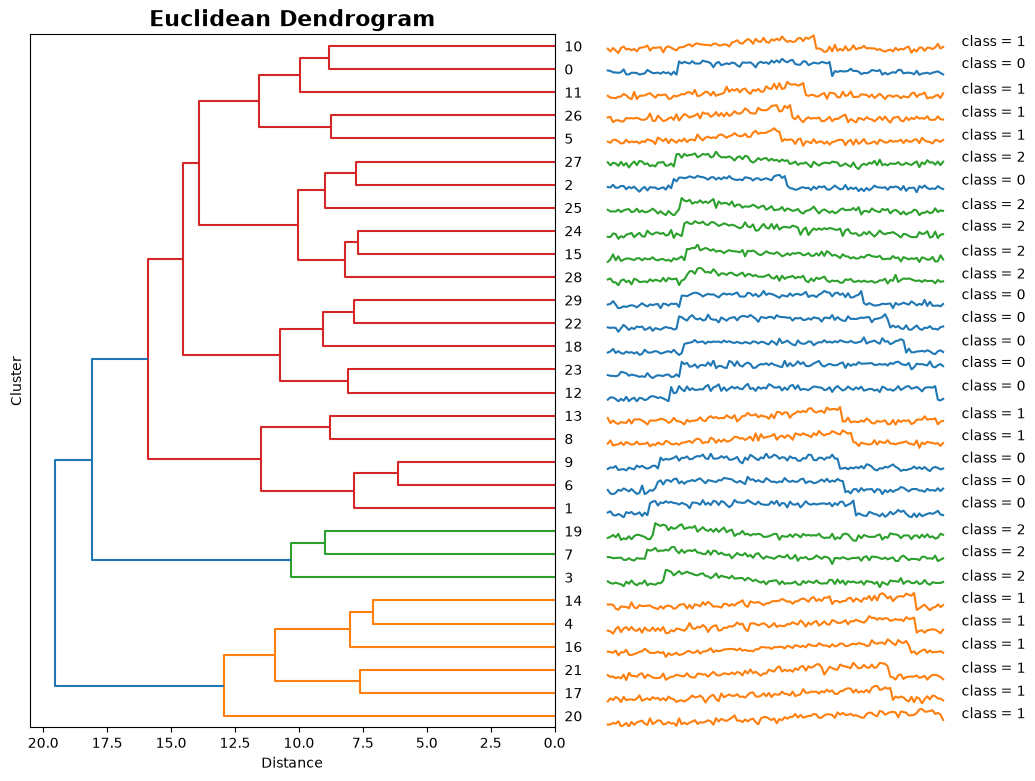

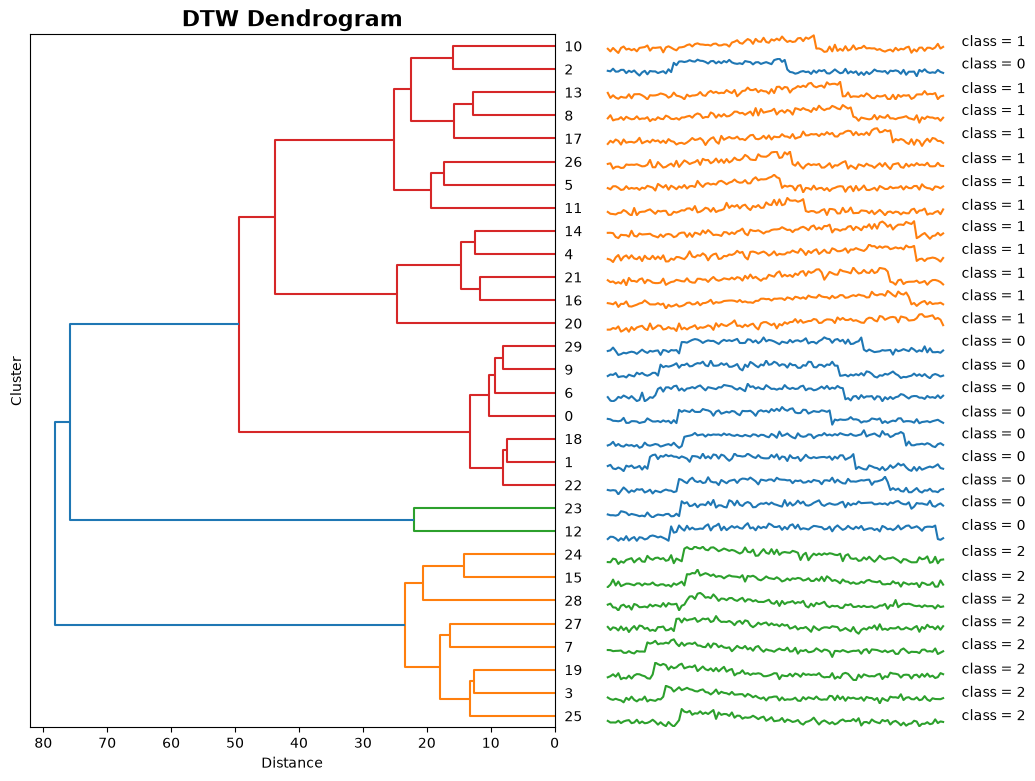

In [14]:
# INSERT YOUR CODE

# Матрицы расстояний (без нормализации)
D_eucl = PairwiseDistance(metric='euclidean', is_normalize=False).calculate(ts_set)
D_dtw = PairwiseDistance(metric='dtw', is_normalize=False).calculate(ts_set)

dx = pd.DataFrame(ts_set.T) # ряды в столбцах, как ожидает plot_dendrogram

# Кластеризация с Евклидовой метрикой
clust_eucl = TimeSeriesHierarchicalClustering(n_clusters=3, method='complete')
clust_eucl.fit(D_eucl)
clust_eucl.plot_dendrogram(dx, labels, title='Euclidean Dendrogram')
plt.show()

# Кластеризация с DTW метрикой 
clust_dtw = TimeSeriesHierarchicalClustering(n_clusters=3, method='complete')
clust_dtw.fit(D_dtw)
clust_dtw.plot_dendrogram(dx, labels, title='DTW Dendrogram')
plt.show()

Сравните результаты иерархической кластеризации, полученные при двух различных функций расстояния, с помощью силуэтного коэффициента. Для этого используйте функцию [`silhouette_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) из библиотеки *sklearn*, передав в нее предвычисленную матрицу расстояний и предсказанные метки.

**Силуэтный коэффициент** – метрика, которая оценивает качество кластеризации на основе исходной выборки и результатов кластеризации без необходимости знания об истинных метках объектов.

Силуэтный коэффициент для выборки показывает, насколько среднее расстояние до объектов своего кластера отличается от среднего расстояния до объектов других кластеров. Пусть дана выборка $X$, состоящая из $N$ объектов. Предположим, что объекты этой выборки были разбиты на кластеры $c_1, ... c_K$, $c_i \in C$, с помощью некоторого алгоритма кластеризации. Тогда силуэтный коэффициент для выборки будет вычисляться следующим образом:

\begin{equation}
sil\_coef = \frac{1}{N} \sum_{c_k \in C} \sum_{x_i \in c_k} \frac{b(x_i, c_k) - a(x_i, c_k)}{\max(a(x_i, c_k), b(x_i, c_k))},
\end{equation}

где $a(x_i, c_k)$ – среднее расстояние от объекта $x_i \in c_k$ до других объектов из этого же кластера $c_k$; <br> $b(x_i, c_k)$  – среднее расстояние от объекта $x_i \in c_k$ до объектов из другого кластера $c_l$, $k \neq l$.

Силуэтный коэффициент принимает значения от  −1  до  1:
*   –1 означает, что кластеры плохие, размытые;
*   0 означает, что кластеры накладываются друг на друга;
*   1 означает, что кластеры плотные и хорошо отделены друг от друга.

Таким образом, чем ближе значение коэффициента к 1, тем лучше кластеризованы данные.

In [15]:
# INSERT YOUR CODE

from sklearn.metrics import silhouette_score

score_eucl = silhouette_score(D_eucl, clust_eucl.labels_, metric='precomputed')
score_dtw  = silhouette_score(D_dtw,  clust_dtw.labels_,  metric='precomputed')

print(f"Silhouette (Euclidean): {score_eucl:.4f}")
print(f"Silhouette (DTW):       {score_dtw:.4f}")

Silhouette (Euclidean): 0.1804
Silhouette (DTW):       0.3881


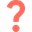
Проанализируйте полученные результаты кластеризации с помощью построенных дендрограмм и вычисленных силуэтных коэффициентов. Какая, на ваш взгляд, функция расстояния показала лучший результат и почему? Укажите, в каких случаях более предпочтительно использовать DTW меру, чем евклидову метрику.

Анализ полученных результатов:
- Euclidean-метрика плохо разделяет классы. Ряды разных классов оказываются в одних и тех же ветвях. Только нижняя ветвь (класс 2 vs класс 1) выглядит приемлимо
- DTW-метрика хорошо разделяет классы. Три большие ветви соответствуют трём классам
- Значение силуэтного коэффициента для DTW более чем в 2 раза больше чем для Евклидовой метрики, что подтверждает визуальную оценку
- Лучший результат показала DTW метрика

Согласно визуализации временных рядов датасета видно, что: временные ряды сдвинуты и растянуты во времени. Евклидова метрика сравнивает точки строго по индексу и чувствительна к таким сдвигам, тогда как DTW выравнивает ряды, сопоставляя похожие участки независимо т их временного положения.

DTW предпочтительнее Евклидовой метрики:
   - Когда временные ряды имеют разную длину.
   - Когда ряды похожи по форме, но сдвинуты по времени
   - Когда ряды имеют разную скорость изменения (один — растянутая
     версия другого)
   - Когда важнее форма сигнала, а не точное соответствие по времени.
   - Когда в данных есть шум, приводящий к локальным сдвигам.

   Евклидова метрика предпочтительнее:
   - Ряды синхронны по времени и одинаковой длины.
   - Нужна быстрая и простая метрика

## **Часть 2.** $Z$-нормализация временных рядов.

### **Задача 5.**
Реализуйте функцию вычисления нормализованного евклидова расстояния между временными рядами `norm_ED_distance()` в модуле *metrics.py* и проверьте правильность своей реализации, сравнив полученные результаты с результатами функции [`ed_distance()`](https://www.sktime.net/en/latest/api_reference/auto_generated/sktime.distances.euclidean_distance.html) из библиотеки *sktime*, в которую необходимо передать <u>нормализованные</u> временные ряды. Для нормализации временных рядов используйте функцию `z-normalize()` из *utils.py*.  Для проверки можно использовать синтетические временные ряды из первой части или заново их сгенерировать.

**Нормализованная евклидова метрика** между двумя временными рядами $T_1$ и $T_2$ длины $n$ вычисляется следующим образом:

\begin{equation}
	\text{ED}_{norm}(T_1, T_2) = \sqrt {\Big|\; 2n\left(1-\dfrac{<T_1, T_2> - \; n \; \cdotp \mu_{T_1} \; \cdotp \mu_{T_2}}{n \; \cdotp \sigma_{T_1} \; \cdotp \sigma_{T_2}}\right)\Big|},
\end{equation}

где $<T_1, T_2>$ – скалярное произведение временных рядов, $\mu_{T_1}$ и $\mu_{T_2}$, $\sigma_{T_1}$ и $\sigma_{T_2}$ – среднее арифметическое и стандартное отклонение временных рядов соответственно.

**Среднее арифметическое** $\mu_T$ и **стандартное отклонение** $\sigma_T$ временного ряда $T$ длины $n$ вычисляются по следующим формулам:

\begin{equation}
	\mu_{T} = \frac{1}{n}\sum\limits_{i=1}^{n} t_{i}, \\[1em]
	\sigma_{T} = \sqrt{\frac{1}{n}\sum\limits_{i=1}^{n} t_i^2-\mu_{T}^2}.
\end{equation}

In [16]:
# INSERT YOUR CODE

n = 100
np.random.seed(42)
ts1 = random_walk(n)
ts2 = random_walk(n)

dist_my = norm_ED_distance(ts1, ts2)

# Нормализуем и считаем обычное евклидово расстояние
ts1_norm = z_normalize(ts1)
ts2_norm = z_normalize(ts2)
dist_sktime = euclidean_distance(ts1_norm, ts2_norm)

print(f"norm_ED_distance:            {dist_my}")
print(f"euclidean_distance(sktime):  {dist_sktime}")

test_distances(dist_sktime, dist_my)

norm_ED_distance:            12.810356611343794
euclidean_distance(sktime):  12.810356611343794


### **Задача 6.**
Далее убедимся, что выполнение $z$-нормализации на этапе предобработки данных имеет важное значение и может повысить точность решаемой задачи.

В данном задании вы продолжите решать задачу иерархической кластеризации. В качестве данных будут использоваться два временных ряда из набора данных [BIDMC](https://physionet.org/content/chfdb/1.0.0/). Набор BIDMC состоит из записей ЭКГ-сигналов, снятых с 15 пациентов с сердечной недостаточностью тяжелой степени.  

Загрузите два временных ряда и визуализируйте их с помощью функции `plot_ts()` из модуля *plots.py*.

In [17]:
url1 = './datasets/part2/chf10.csv'
ts1 = read_ts(url1)

url2 = './datasets/part2/chf11.csv'
ts2 = read_ts(url2)

In [18]:
ts_set = np.concatenate((ts1, ts2), axis=1).T

In [19]:
plot_ts(ts_set)

Разделите каждый временной ряд на непересекающиеся подпоследовательности с помощью техники скользящего окна. Для этого используйте функцию `sliding_window()` из модуля *utils.py*, передав в нее временной ряд, заданную длину подпоследовательности и величину шага. В нашем случае, величина шага равна длине подпоследовательности.

In [20]:
m = 125
subs_set1 = sliding_window(ts_set[0], m, m-1)
subs_set2 = sliding_window(ts_set[1], m, m-1)

Сформируйте множество всех подпоследовательностей, извлеченных из двух временных рядов, и массив меток подпоследовательностей в соответствии с их принадлежностью к временному ряду.

In [21]:
subs_set = np.concatenate((subs_set1[0:15], subs_set2[0:15]))
labels = np.array([0]*subs_set1[0:15].shape[0] + [1]*subs_set2[0:15].shape[0])

Добавьте в класс `PairwiseDistance` из модуля *pairwise_distance.py* возможность вычисления нормализованной евклидовой метрики между временными рядами. Если матрица расстояний строится для нормализованных временных рядов на основе евклидовой метрики, то должна вызываться функция `norm_ED_distance()`. Для остальных метрик/мер схожести перед нахождением матрицы расстояний временные ряды должны подтвергаться $z$-нормализации с помощью функции `z_normalize()` из модуля *utils.py*.

Далее выполните иерархическую кластеризацию подпоследовательностей двух временных рядов с использованием предварительно построенных матриц расстояний на основе классической и нормализованной евклидовой метрики.

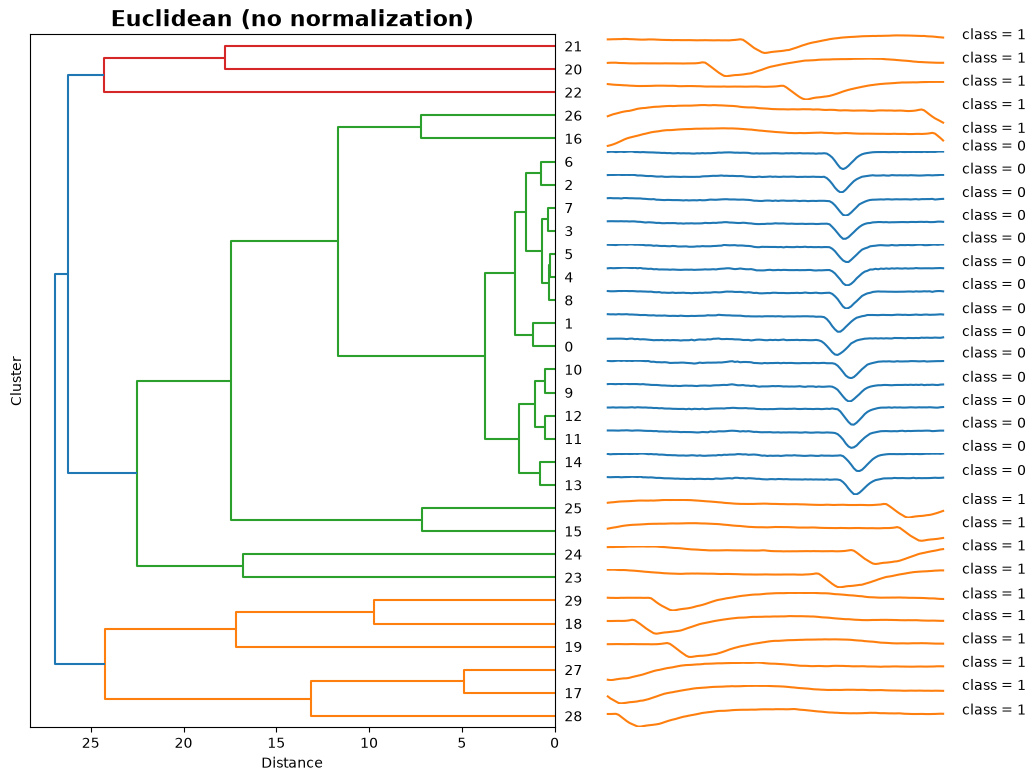

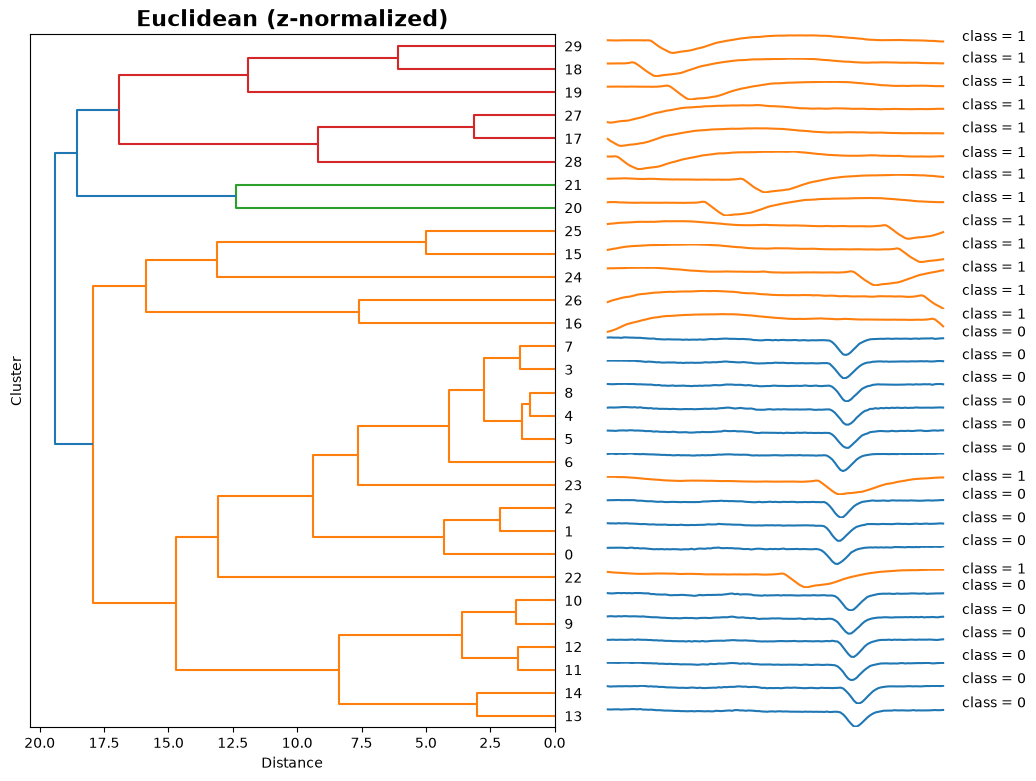

In [22]:
# INSERT YOUR CODE
# Матрицы расстояний для
# Евклидовой метрики без нормализации
D_eucl = PairwiseDistance(metric='euclidean', is_normalize=False).calculate(subs_set)

# Нормализованной Евклидовой метрика
D_norm = PairwiseDistance(metric='euclidean', is_normalize=True).calculate(subs_set)

dx = pd.DataFrame(subs_set.T) # ряды в столбцах, как ожидает plot_dendrogram

# Кластеризация с Евклидовой метрикой без нормализации
clust_eucl = TimeSeriesHierarchicalClustering(n_clusters=2, method='complete')
clust_eucl.fit(D_eucl)
clust_eucl.plot_dendrogram(dx, labels, title='Euclidean (no normalization)')
plt.show()

# Кластеризация с Евклидовой метрикой с нормализацией
clust_norm = TimeSeriesHierarchicalClustering(n_clusters=2, method='complete')
clust_norm.fit(D_norm)
clust_norm.plot_dendrogram(dx, labels, title='Euclidean (z-normalized)')
plt.show()

Вычислите силуэтные коэффициенты для оценки качества кластеризации с нормализацией и без нее, как это было сделано в задаче 4 части 1.

In [23]:
# INSERT YOUR CODE

score_eucl = silhouette_score(D_eucl, clust_eucl.labels_, metric='precomputed')
score_norm = silhouette_score(D_norm, clust_norm.labels_, metric='precomputed')

print(f"Silhouette (no normalization): {score_eucl:.4f}")
print(f"Silhouette (z-normalized):     {score_norm:.4f}")

Silhouette (no normalization): 0.4183
Silhouette (z-normalized):     0.3275


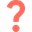
Сравните полученные результаты кластеризации с помощью построенных дендрограмм и вычисленных силуэтных коэффициентов. Позволила ли $z$-нормализации временных рядов повысить качество кластеризации?

Анализ результатов кластеризации:

1. Без нормализации (Silhouette = 0.4183):
   - Дендрограмма показывает чёткое разделение: два крупных кластера класса 1 (верхний и нижний) и один большой кластер класса 0 (средний). Только 4 ряда класса 1 попали к кластеру класса 0.

2. С z-нормализацией (Silhouette = 0.3275):
   - Дендрограмма показывает более слабое разделение: класс 1 «разорван» на три части, а класс 0 перемешан с классом 1 в двух нижних ветвях. Силуэтный коэффициент ниже, чем без нормализации.

3. Вывод:
   В данном случае z-нормализация понизила качество кластеризации.
   
   Данные подпоследовательности больше различаются амплитудой сигнала и его уровнем, а не формой. Ряды класса 1 имеют большую амплитуду и
   выраженные колебания, ряды класса 0 малую амплитуду и более горизонтальный профиль.
   
   После z-нормализации каждый ряд приводится к единичной дисперсии, и различие в амплитуде становится менее выраженным. Форма сигналов похожа сердечных сокращений похожа. Поэтому классы перемешиваются.
   
   Таким образом, z-нормализация полезна, когда нужно сравнивать форму сигналов, а не масштаб. Если различия между классами в первую очередь связаны с амплитудой или уровнем сигнала нормализация может ухудшить качество кластеризации.

## **Часть 3.** Классификация изображений, представленных в виде временных рядов.

### **Задача 7.**
В данном задании вам предстоит выполнить преобразование изображения, на котором находится некоторый объект, во временной ряд. Для этого вы реализуете один из существующих методов, предложенный в [статье Кеога и др](https://dl.acm.org/doi/10.5555/1182635.1164203).

Данный метод заключается в том, что сначала на изображении выполняется поиск контура $E = \{e_i\}_{i=1}^L$, где $e_i$ – точки контура, и центра масс объекта $O$. Затем берутся точки, расположенные на контуре объекта, следующим образом.

Рассмотрим луч $OP$ с началом в центре масс объекта $O$, направление которого совпадает с положительным направлением оси Ox (см. рисунок). Далее выполняется поворот против часовой стрелки луча $OP$ вокруг центра масс $O$ на некоторый заданный угол $α$, $1° \leqslant α \leqslant 360°$. Поворот луча будет осуществляться до тех пор, пока луч не пройдет полный оборот. Все точки $P = \{P_i\}_{i=1}^K$, $P_i \in E$, $K = \lfloor \frac{360°}{α} \rfloor$, образованные пересечением луча $OP$ с контуром $E$ во время поворота, будут являться искомыми.

На завершающем шаге метода вычисляются расстояния между центром масс объекта $O$ и найденными точками на контуре $P$. В качестве функции расстояния может быть использовано манхэттенское или евклидово расстояние. Полученные расстояния будут формировать временной ряд $T$ длины $K$:
\begin{equation}
T = \{t_i\}_{i=1}^K,\;где \; t_i = dist(O, P_i), \; P_i \in P.
\end{equation}

\
<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/01%20Basics/img/image2ts.png?raw=true" width="1000"></center>

Поскольку часть 3 предполагает работу с изображениями, то вы будете использовать для реализации некоторых частей кода библиотеку компьютерного зрения *cv2*. Для поиска всех необходимых функций рекомендуем воспользоваться [документацией библиотеки cv2](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html).

Загрузите изображение *example.tif* из директории *./datasets/part3* и выполните его визуализацию с помощью соответствующих функций из библиотеки *cv2*.

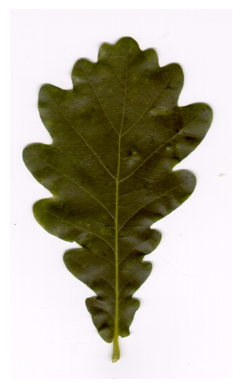

In [24]:
# INSERT YOUR CODE

img = cv2.imread('./datasets/part3/example.tif')
cv2_imshow(img)


За конвертацию изображения во временной ряд с помощью описанного выше метода отвечает функция `image2ts()` из модуля *image_converter.py*. Прежде чем исходное изображение будет преобразовано во временной ряд, сначала оно должно пройти этап предварительной обработки. Предварительная обработка включает в себя следующие шаги:

<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/01%20Basics/img/image_preprocessing.png?raw=true" width="1000"></center>

Предобработка изображения в `image2ts()` осуществляется с помощью функции `_img_preprocess()`. Реализуйте в данной функции все представленные на диаграмме шаги предварительной обработки средствами библиотеки *cv2*. Промежуточные результаты должны совпадать с представленными на диаграмме.

Далее выполните конвертацию изображения во временной ряд, передав в функцию `image2ts()` следующие заданные вами аргументы:
*   исходное загруженное изображение;
*   шаг угла поворота;
*   параметр, определяющий нужно или нет визуализировать изображение с выделенными на нем контуром, центром масс и лучами, проведенными из центра.

Визуализируйте полученный временной ряд.


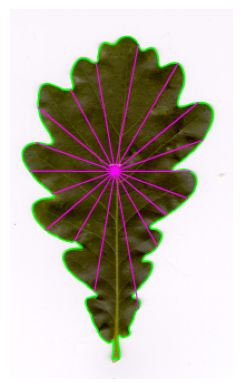

In [25]:
angle_step = 20
visualize = True

ts = image2ts(img, angle_step, visualize)
plot_ts(np.array([ts]), "Time series representation of image")

### **Задача 8.**

Выполните классификацию изображений, представленных в виде временных рядов, с помощью метода $k$ ближайших соседей (kNN).

**Метод $k$ ближайших соседей (kNN)** – алгоритм классификации, заключающийся в вычислении сходства между объектами на основе некоторой заданной метрики/меры схожести. Классифицируемый объект относится к тому классу, к которому принадлежит большинство из его $k$ соседей ($k$ ближайших к нему объектов из обучающей выборки).

Для классификации на основе алгоритма kNN необходимо выполнить следующие шаги:

1. Загрузить обучающую и тестовую выборки.

2. Задать параметр алгоритма $k$, где $k$ – количество ближайших соседей, $k \in \mathbb N^*$.

3. Для каждого объекта из тестовой выборки выполнить следующее:

    3.1. Вычислить расстояние до всех объектов из обучающей выборки на основе заданной метрики/меры схожести.
    
    3.2. Отсортировать в порядке возрастания найденные расстояния.

    3.3. Найти $k$ ближайших соседей, взяв первые $k$ минимальные расстояния из отсортированного массива расстояний.

    3.4. Назначить объекту из тестовой выборки наиболее часто встречающийся класс найденных ранее ближайших соседей.


Для этого задания вам предлагается набор данных, который содержит изображения листьев четырех различных пород деревьев: дуб, ольха, ива и липа. Набор данных состоит из обучающей и тестовой выборок, включающих по 15 и 10 изображений листьев на класс соответственно. Для составления этого набора данных изображения были взяты из [Swedish Leaf Dataset](https://www.cvl.isy.liu.se/en/research/datasets/swedish-leaf/).

Загрузите изображения из обучающей и тестовой выборок, а также их метки, используя `read_images()` и `read_ts()` соответственно.
Выполните визуализацию прецедентов выборки с помощью функции `plot_images()`.


In [26]:
def read_images(dir: str) -> list[np.ndarray]:
    """
    Load all images from a directory

    Parameters
    ----------
    dir: directory path

    Returns
    -------
    images: images from a directory
    """

    images = []
    for img_path in sorted(glob.glob(dir)):
        cv_img = cv2.imread(img_path)
        images.append(cv_img)

    return images

In [27]:
def plot_images(images: list[np.ndarray], labels: np.ndarray, class_names: list[str]) -> None:
    """
    Plot some images from dataset

    Parameters
    ----------
    images: dataset of images
    labels: labels of images
    class_names: class names of images
    """

    rows = 2
    columns = 4

    fig, axes = plt.subplots(nrows=rows, ncols=columns, figsize=(columns*2, rows*3))

    for num in range(1, rows*columns+1):
        fig.add_subplot(rows, columns, num)
        idx = num - 1
        plt.imshow(images[idx], aspect='auto')
        plt.title(f'{class_names[labels[idx]]}', fontsize=10)

    fig.tight_layout()

    for idx, ax in enumerate(axes.flat):
        ax.set_xticks([])
        ax.set_yticks([])

In [28]:
train_set_path = "./datasets/part3/train_set_leaves/*.tif"
test_set_path = "./datasets/part3/test_set_leaves/*.tif"

train_images = read_images(train_set_path)
test_images = read_images(test_set_path)

train_label_path = './datasets/part3/train_set_leaves/train_label.csv'
test_label_path = './datasets/part3/test_set_leaves/test_label.csv'

train_labels = read_ts(train_label_path)
train_labels = train_labels.reshape(-1).astype('int32')

test_labels = read_ts(test_label_path)
test_labels = test_labels.reshape(-1).astype('int32')

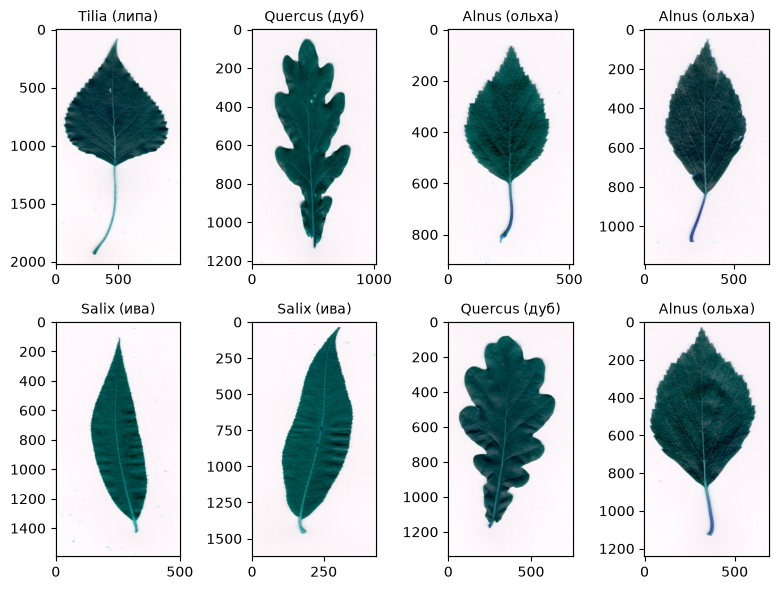

In [29]:
class_names = ['Quercus (дуб)', 'Alnus (ольха)', 'Salix (ива)', 'Tilia (липа)']
plot_images(train_images, train_labels, class_names)

Выполните преобразование изображений обучающей и тестовой выборок во временные ряды с помощью функции `image2ts()`.  

In [30]:
# INSERT YOUR CODE

train_ts = np.array([image2ts(img, angle_step=5, is_visualize=False) for img in train_images])
test_ts  = np.array([image2ts(img, angle_step=5, is_visualize=False) for img in test_images])

Для классификации временных рядов методом $k$ ближайших соседей вам необходимо использовать класс `TimeSeriesKNN` из модуля *classification.py*.
Реализуйте метод `fit()` в классе `TimeSeriesKNN`, который выполняет поиск для каждого элемента из тестовой выборки $k$ ближайших соседей и назначает им тот класс, который является часто встречающимся среди классов ближайших соседей. В качестве параметров в метод `fit()` передается тестовая выборка. Вычислите точность классификации по метрике accuracy с помощью функции `calculate_accurary()` из модуля *classification.py*.

In [31]:
n_neighbors = 6
metric = 'euclidean'
metric_params = {'normalize': True}

# INSERT YOUR CODE

knn = TimeSeriesKNN(n_neighbors=n_neighbors, metric=metric, metric_params=metric_params)
knn.fit(train_ts, train_labels)
y_pred = knn.predict(test_ts)

accuracy_eucl = calculate_accuracy(test_labels, y_pred)
print(f"Accuracy (euclidean, normalized): {accuracy_eucl:.4f}")

Accuracy (euclidean, normalized): 0.7250


In [32]:
metric = 'dtw'
metric_params = {'normalize': True}

# INSERT YOUR CODE

knn = TimeSeriesKNN(n_neighbors=n_neighbors, metric=metric, metric_params=metric_params)
knn.fit(train_ts, train_labels)
y_pred = knn.predict(test_ts)

accuracy_dtw = calculate_accuracy(test_labels, y_pred)
print(f"Accuracy (dtw, normalized): {accuracy_dtw:.4f}")

Accuracy (dtw, normalized): 0.8000


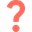
Проанализируйте результаты и сделайте выводы.

DTW-мера показала лучший результат (80% > 72.5%). Это объясняется тем, что временные ряды, полученные из изображений листьев, могут быть сдвинуты или деформированы относительно друг друга (из-за разницы в размерах листьев например). DTW выравнивает такие ряды, сопоставляя похожие участки, тогда как евклидова метрика сравнивает точки строго по позиции и чувствительна к сдвигам.

   DTW предпочтительнее для классификации листьев, потому что:
   - форма листа важнее точного временного соответствия
   - листья одного класса могут быть различны по размерам, и тогда будет растянут или сжат по амплитуде соответствующий временной ряд
   - листья ориентированы по разному, не в точном соответствии, угол 0 будет соответствовать различным точкам контура, следовательно будет сдвиг временного ряда

Евклидова метрика предпочтительнее, когда ряды синхронны и одинаковы по масштабу, а также когда важна скорость вычислений